### Part 2: Employee Attrition and Retention Analysis

In [1]:
# Import libraries:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
import pandas as pd
df = pd.read_csv(r"C:\Users\vssag\Desktop\Task 2.csv")

### Understanding the data set.

In [3]:
df.sample(5) # It will give random 5 rows.

,Employee ID,Department,Age,Gender,Job Satisfaction,Salary,Years at Company,Promotion History,Attrition Status
1813,EMP11814,HR,38.0,Male,3.0,50000.0,7.2,No,Left
718,EMP10719,Operations,38.0,Male,5.0,37500.0,4.0,No,NO
1292,EMP11293,Finance,53.0,Female,2.0,90500.0,9.5,Yes,N
1908,EMP11909,Marketing,36.0,Female,3.0,55500.0,8.2,Yes,STAYED
709,EMP10710,Finance,29.0,Female,4.0,59000.0,2.0,No,No


In [4]:
df.head() # It shows top five rows

,Employee ID,Department,Age,Gender,Job Satisfaction,Salary,Years at Company,Promotion History,Attrition Status
0,EMP10001,Operations,47.0,Male,2.0,53500.0,2.9,No,YES
1,EMP10002,IT,29.0,Female,4.0,59000.0,0.4,No,Yes
2,EMP10003,Marketing,29.0,Female,4.0,65000.0,9.6,No,Y
3,EMP10004,Operations,46.0,Female,4.0,57000.0,3.5,No,Active
4,EMP10005,Sales,36.0,unknown,1.0,50000.0,2.3,Yes,Stayed


In [5]:
df.head() # It shows top five rows

,Employee ID,Department,Age,Gender,Job Satisfaction,Salary,Years at Company,Promotion History,Attrition Status
0,EMP10001,Operations,47.0,Male,2.0,53500.0,2.9,No,YES
1,EMP10002,IT,29.0,Female,4.0,59000.0,0.4,No,Yes
2,EMP10003,Marketing,29.0,Female,4.0,65000.0,9.6,No,Y
3,EMP10004,Operations,46.0,Female,4.0,57000.0,3.5,No,Active
4,EMP10005,Sales,36.0,unknown,1.0,50000.0,2.3,Yes,Stayed


In [6]:
df.tail() # It shows top last rows

,Employee ID,Department,Age,Gender,Job Satisfaction,Salary,Years at Company,Promotion History,Attrition Status
2673,EMP12674,Finance,37.0,Male,2.0,73500.0,1.6,Not Yet,Stayed
2674,EMP12675,Operations,53.0,Male,3.0,70500.0,8.4,Yes,Stayed
2675,EMP12676,Finance,35.0,Male,5.0,68500.0,5.3,No,STAYED
2676,EMP12677,Finance,46.0,Female,3.0,61000.0,1.8,Not Yet,N
2677,EMP12678,Marketing,28.0,Male,4.0,57500.0,1.8,Not Yet,NO


In [7]:
print(df.columns.tolist()) # It shows All column names in a list.

['Employee ID', 'Department', 'Age', 'Gender', 'Job Satisfaction', 'Salary', 'Years at Company', 'Promotion History', 'Attrition Status']


In [8]:
df.info() # It will give Dataset structure. 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2678 entries, 0 to 2677
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee ID        2678 non-null   object 
 1   Department         2646 non-null   object 
 2   Age                2652 non-null   float64
 3   Gender             2630 non-null   object 
 4   Job Satisfaction   2612 non-null   float64
 5   Salary             2638 non-null   float64
 6   Years at Company   2646 non-null   float64
 7   Promotion History  2612 non-null   object 
 8   Attrition Status   2678 non-null   object 
dtypes: float64(4), object(5)
memory usage: 188.4+ KB


In [9]:
df.describe() # It shows statistical summary of the dataset

,Age,Job Satisfaction,Salary,Years at Company
count,2652.000000,2612.000000,2638.000000,2646.000000
mean,34.110483,3.249234,58258.529189,4.624565
std,7.634488,1.134189,14563.666187,3.215006
min,21.000000,1.000000,18000.000000,0.100000
25%,28.000000,3.000000,48000.000000,2.300000
50%,34.000000,3.000000,57000.000000,3.900000
75%,39.000000,4.000000,68000.000000,6.100000
max,60.000000,5.000000,108000.000000,25.000000


In [10]:
df.dtypes # it will shows Data types of columns.

Employee ID           object
Department            object
Age                  float64
Gender                object
Job Satisfaction     float64
Salary               float64
Years at Company     float64
Promotion History     object
Attrition Status      object
dtype: object

### Data Quality Checking

In [11]:
df.isnull().any() # Check any missing value in dataset by each column.

Employee ID          False
Department            True
Age                   True
Gender                True
Job Satisfaction      True
Salary                True
Years at Company      True
Promotion History     True
Attrition Status     False
dtype: bool

In [12]:
df.isnull().sum() # It shows all misiing not/nll in each column.

Employee ID           0
Department           32
Age                  26
Gender               48
Job Satisfaction     66
Salary               40
Years at Company     32
Promotion History    66
Attrition Status      0
dtype: int64

#  Tasks:

### 1. Clean the dataset and identify inconsistent attrition labels.

In [13]:
df["Department"].unique()        # Check department labels

array(['Operations', 'IT', 'Marketing', 'Sales', 'Customer Support',
       'Finance', 'HR', nan], dtype=object)

In [14]:
df["Gender"].unique()            # Check gender labels

array(['Male', 'Female', ' unknown ', nan], dtype=object)

In [15]:
df["Promotion History"].unique() # Check promotion labels

array(['No', 'Yes', 'Not Yet', nan], dtype=object)

In [16]:
df["Attrition Status"].unique()  # Check attrition labels

array(['YES ', 'Yes', 'Y', 'Active', 'Stayed', 'STAYED', 'NO ', 'N',
       'Left', 'No', 'LEFT', 'Resigned'], dtype=object)

In [17]:
df["Department"].unique()  # Check department names

array(['Operations', 'IT', 'Marketing', 'Sales', 'Customer Support',
       'Finance', 'HR', nan], dtype=object)

In [18]:
df["Department"] = df["Department"].str.strip().str.title().replace({  # Correct inconsistent department names
    "Hr": "Human Resources",
    "I.T.": "IT"
})

In [19]:
df["Department"].unique()  # Check department names again

array(['Operations', 'It', 'Marketing', 'Sales', 'Customer Support',
       'Finance', 'Human Resources', nan], dtype=object)

In [20]:
df["Gender"] = df["Gender"].str.strip().str.title()  # Correct inconsistent gender values


In [21]:
df["Gender"].unique()  # Check unique values again

array(['Male', 'Female', 'Unknown', nan], dtype=object)

In [22]:
df["Promotion History"] = df["Promotion History"].str.strip().str.title()  # Correct inconsistent values

In [23]:
df["Promotion History"].unique()  # Check unique values again

array(['No', 'Yes', 'Not Yet', nan], dtype=object)

In [24]:
df["Attrition Status"] = df["Attrition Status"].str.strip().str.upper().replace({  # Standardize attrition values
    "Y": "YES",
    "LEFT": "YES",
    "RESIGNED": "YES",
    "N": "NO",
    "STAYED": "NO",
    "ACTIVE": "NO"
})

In [25]:
df["Attrition Status"].unique()  # Check unique values again

array(['YES', 'NO'], dtype=object)

In [26]:
df.isnull().sum()  # Check missing values in each column

Employee ID           0
Department           32
Age                  26
Gender               48
Job Satisfaction     66
Salary               40
Years at Company     32
Promotion History    66
Attrition Status      0
dtype: int64

In [27]:
df["Department"].mode()  # Find most frequent department

0    Operations
Name: Department, dtype: object

In [28]:
df["Department"] = df["Department"].fillna(df["Department"].mode()[0])  # Fill missing values with mode

In [29]:
df["Age"].describe()  # Check age Statistical summary.

count    2652.000000
mean       34.110483
std         7.634488
min        21.000000
25%        28.000000
50%        34.000000
75%        39.000000
max        60.000000
Name: Age, dtype: float64

In [30]:
df["Age"] = df["Age"].fillna(df["Age"].median())  # Fill missing values with median

In [31]:
df["Gender"].value_counts()  # Check gender distribution

Gender
Male       1516
Female     1102
Unknown      12
Name: count, dtype: int64

In [32]:
df["Gender"] = df["Gender"].fillna("Unknown")  # Fill missing gender values

In [33]:
df["Gender"].isnull().sum()  # Check missing values again

np.int64(0)

In [34]:
df["Job Satisfaction"].describe()  # Check statistical distribution

count    2612.000000
mean        3.249234
std         1.134189
min         1.000000
25%         3.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: Job Satisfaction, dtype: float64

In [35]:
df["Job Satisfaction"] = df["Job Satisfaction"].fillna(df["Job Satisfaction"].median())  # Fill missing values with median

In [36]:
df["Job Satisfaction"].isnull().sum()  # Check missing values again


np.int64(0)

In [37]:
df["Salary"].describe()  # Check statistical distribution

count      2638.000000
mean      58258.529189
std       14563.666187
min       18000.000000
25%       48000.000000
50%       57000.000000
75%       68000.000000
max      108000.000000
Name: Salary, dtype: float64

In [38]:
df["Salary"] = df["Salary"].fillna(df["Salary"].median())  # Fill missing values with median

In [39]:
df["Salary"].isnull().sum()  # Check missing values again

np.int64(0)

In [40]:
df["Years at Company"].describe()  # Check statistical distribution

count    2646.000000
mean        4.624565
std         3.215006
min         0.100000
25%         2.300000
50%         3.900000
75%         6.100000
max        25.000000
Name: Years at Company, dtype: float64

In [41]:
df["Years at Company"] = df["Years at Company"].fillna(df["Years at Company"].median())  # Fill missing values with median

In [42]:
df["Years at Company"].isnull().sum()  # Check missing values again

np.int64(0)

In [43]:
df["Promotion History"] = df["Promotion History"].fillna("Unknown")  # Replace missing values with Unknown

In [44]:
df["Promotion History"].isnull().sum()  # Check missing values again

np.int64(0)

In [45]:
df["Attrition Status"] = df["Attrition Status"].fillna("Unknown")  # Replace missing values with Unknown

In [46]:
df["Attrition Status"].isnull().sum()  # Check missing values again

np.int64(0)

In [47]:
df.isnull().sum()  # Check remaining missing values

Employee ID          0
Department           0
Age                  0
Gender               0
Job Satisfaction     0
Salary               0
Years at Company     0
Promotion History    0
Attrition Status     0
dtype: int64

### 2. Calculate the overall employee attrition rate.

In [48]:
df["Attrition Status"].value_counts()

Attrition Status
NO     2062
YES     616
Name: count, dtype: int64

In [49]:
COUNT = (df["Attrition Status"] == "NO").mean()*100
print(COUNT)

76.99775952203136


### 3. Calculate attrition rates by department, age group, and salary category.

In [50]:
pd.crosstab(df['Department'], df['Attrition Status'], normalize='index')['NO'] * 100

Department
Customer Support    72.390572
Finance             81.873112
Human Resources     74.162679
It                  79.157895
Marketing           74.349442
Operations          79.965753
Sales               73.684211
Name: NO, dtype: float64

In [51]:
df['Age Group'] = 'Senior'
df.loc[df['Age'] < 40, 'Age Group'] = 'Middle'
df.loc[df['Age'] < 30, 'Age Group'] = 'Young'

pd.crosstab(df['Age Group'], df['Attrition Status'], normalize='index')["YES"] * 100

Age Group
Middle    21.840000
Senior    23.987539
Young     24.045802
Name: YES, dtype: float64

In [52]:
df["Salary Group"]="Highesh Paying Employees"
df.loc[df["Salary"].between(18000,50000),"Salary Group"] = "Lowest Paying Employess"
df.loc[df["Salary"].between(50000,95000),"Salary Group"] = "Mid Paying Employees"


pd.crosstab(df["Salary Group"],df["Attrition Status"],normalize='index')["YES"]*100

Salary Group
Highesh Paying Employees    23.809524
Lowest Paying Employess     25.566751
Mid Paying Employees        21.900161
Name: YES, dtype: float64

### 4. Analyze the relationship between years at the company and attrition status.

In [53]:
df["Years at Company Group"] = "Experienced Employees"
df.loc[df["Years at Company"] > 2,"Years at Company Group"] ="Fresher Employees"
df.loc[df["Years at Company"].between(3,5),"Years at Company Group"] = "Mid Level Experienced Employees"


pd.crosstab(df["Years at Company Group"],df["Attrition Status"],normalize='index')['YES']*100

Years at Company Group
Experienced Employees              26.247689
Fresher Employees                  21.660377
Mid Level Experienced Employees    23.029557
Name: YES, dtype: float64

In [54]:
df.groupby("Attrition Status")["Job Satisfaction"].mean()*100

Attrition Status
NO     338.797284
YES    275.811688
Name: Job Satisfaction, dtype: float64

# Visualization Tasks:


### 6. Create a bar chart showing department-wise attrition rates.

In [55]:
# Calculate department-wise attrition rate

dept_attrition = df.groupby("Department")["Attrition Status"].value_counts(normalize=True).unstack() * 100

dept_attrition = dept_attrition["YES"]  # Get attrition rate
print(dept_attrition)

Department
Customer Support    27.609428
Finance             18.126888
Human Resources     25.837321
It                  20.842105
Marketing           25.650558
Operations          20.034247
Sales               26.315789
Name: YES, dtype: float64


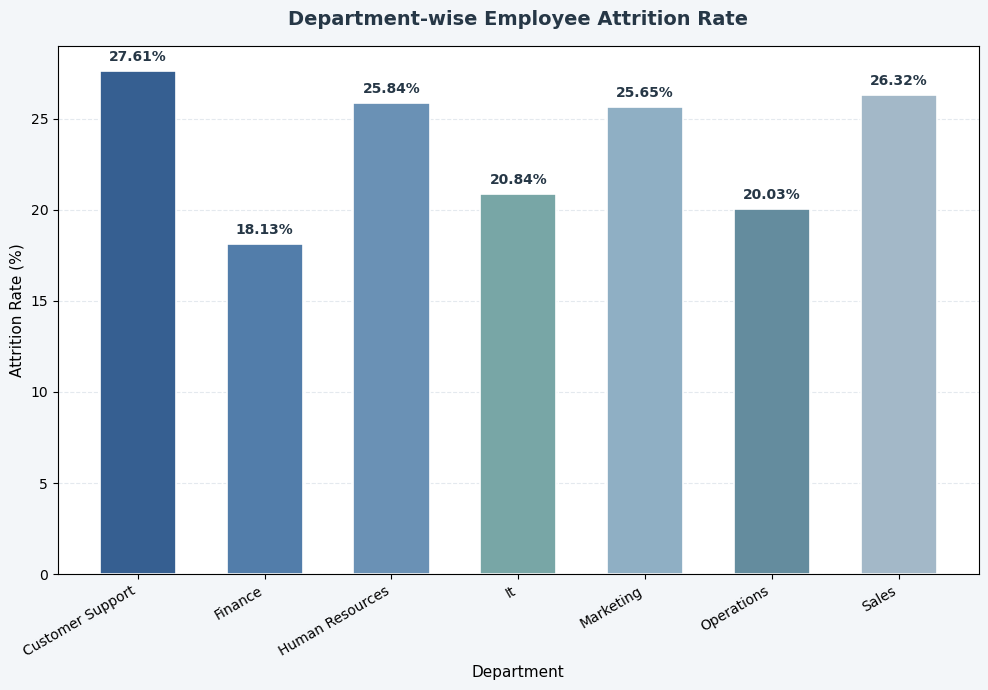

In [59]:
plt.figure(figsize=(10, 7), facecolor="#F3F6F9")
ax = plt.gca()
ax.set_facecolor("#FFFFFF")

colors = ["#365F91", "#527DAA", "#6A91B5", "#78A6A6",
          "#8FAFC4", "#648C9E", "#A3B8C8"]

bars = plt.bar(dept_attrition.index, dept_attrition.values,
               color=colors[:len(dept_attrition)],
               edgecolor="#FFFFFF", linewidth=1.2, width=0.6)

plt.title("Department-wise Employee Attrition Rate",
          fontsize=14, fontweight="bold", color="#263746", pad=15)
plt.xlabel("Department", fontsize=11)
plt.ylabel("Attrition Rate (%)", fontsize=11)

plt.bar_label(bars, fmt="%.2f%%", padding=5,
              fontsize=10, fontweight="bold", color="#263746")  # Show values above bars

plt.grid(axis="y", linestyle="--", color="#D9E1E8", alpha=0.7)
ax.set_axisbelow(True)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Create a histogram of employee tenure.


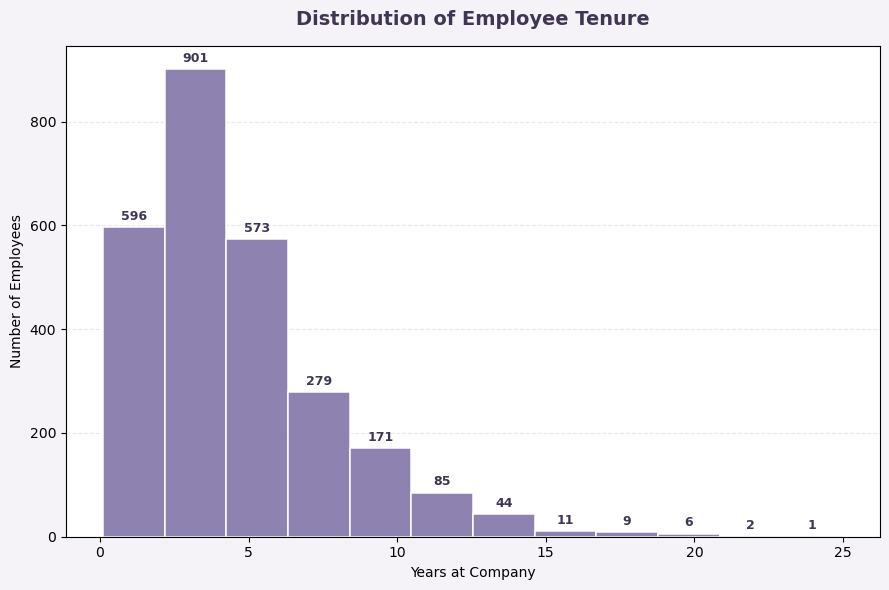

In [61]:
employee = df["Years at Company"]  #

plt.figure(figsize=(9, 6), facecolor="#F5F3F8") 
ax = plt.gca()  # Get current axes
ax.set_facecolor("#FFFFFF")  # Set plot background

counts, bins, patches = plt.hist(
    employee, bins=12,  # Divide data into 12 intervals
    color="#8276A8",
    edgecolor="#FFFFFF",
    linewidth=1.2,
    alpha=0.9)

plt.title("Distribution of Employee Tenure",
          fontsize=14, fontweight="bold", color="#403653", pad=15)  

plt.xlabel("Years at Company") 
plt.ylabel("Number of Employees")  

plt.bar_label(
    patches,
    labels=[str(int(x)) if x > 0 else "" for x in counts],
    padding=3, fontsize=9, fontweight="bold",
    color="#403653"
)  

plt.grid(axis="y", linestyle="--", color="#E3DDEC", alpha=0.7)
ax.set_axisbelow(True)  # Keep grid behind bars

plt.tight_layout()  # Adjust chart spacing
plt.show()  

### 8. Create a stacked bar chart comparing attrition status across job satisfaction categories.


<Figure size 1000x600 with 0 Axes>

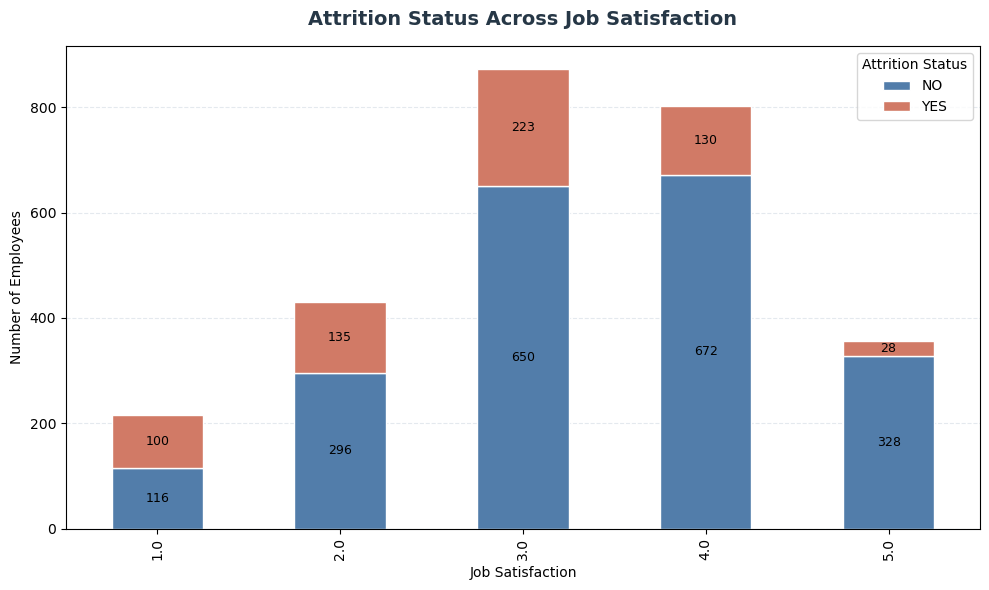

In [62]:
left = df[df["Attrition Status"] == "YES"].groupby("Job Satisfaction").size()  # Count employees who left
stayed = df[df["Attrition Status"] == "NO"].groupby("Job Satisfaction").size()  # Count employees who stayed

data = pd.DataFrame({"NO": stayed, "YES": left}).fillna(0)  # Combine both counts

plt.figure(figsize=(10, 6), facecolor="#F3F6F9")  # Set chart size and background

ax = data.plot.bar(
    stacked=True,
    figsize=(10, 6),
    color=["#527DAA", "#D17A66"],
    edgecolor="white",
    linewidth=1) 

ax.set_facecolor("#FFFFFF")  # Set plot background

plt.xlabel("Job Satisfaction")
plt.ylabel("Number of Employees")
plt.title("Attrition Status Across Job Satisfaction",
          fontsize=14, fontweight="bold", color="#263746", pad=15)

plt.legend(title="Attrition Status")
plt.grid(axis="y", linestyle="--", color="#D9E1E8", alpha=0.7)
ax.set_axisbelow(True)  # Keep grid behind bars

for container in ax.containers:
    ax.bar_label(container, label_type="center", fontsize=9)  # Show employee counts

plt.tight_layout()  # Adjust chart spacing
plt.show()  

### 9. Identify employee segments with comparatively high attrition rates.

I checked different employee groups to find out which employees were leaving the company more.

The results showed that:

1. **Department:** Customer Support had the highest attrition rate (27.61%).
2. **Age Group:** Young employees had a higher attrition rate (24.05%).
3. **Salary:** Employees in the Low Salary group had the highest rate (25.57%).
4. **Job Satisfaction:** Employees with a satisfaction score of 1 had the highest rate (46.30%).
5. **Gender:** Male employees had a higher rate (23.55%) than female employees.
6. **Experience:** Experienced employees had the highest rate (26.25%).
7. **Promotion History:** Employees with no promotion history had a higher rate (26.40%).

**Conclusion:** From the analysis, I found that employees with low job satisfaction, lower salaries, and those working in Customer Support were more likely to leave the company.

### 10. Strategies that could be used:
1. **Low Salary** - Increase the employees' salary so that they do not leave due to low pay.
2. **Not Happy with Job** - Ask employees why they are not happy with their job and try to resolve their issues.
3. **Promotions** - Give experienced employees promotions at the right time so that they feel appreciated and have opportunities to progress.
4. **Customer Support** - Give employees proper breaks as it can be a stressful job.
5. **Young Employees** - Give young employees proper training so that they understand what they are doing and can do their job better.
6. **Reward Employees** - Reward employees or give them bonuses if they do well.
7. **Flexible Hours** - Give employees some flexibility with their hours.
8. **Skill Development** - Provide training so employees can learn new skills and improve their performance.
9. **Work Environment** - Maintain a friendly work environment where employees feel comfortable.
10. **Manager Support** - Managers should listen to employees and help them when they face problems at work.